## Import

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

## Setup

In [2]:
assert os.path.exists("weights_V3_0/classification_lightgbm_test_metrics.json"), "run classification_lightgbm_V3_0.ipynb first"
SEED = 42
np.random.seed(SEED)
boost_rng = np.random.RandomState(SEED)  # separate stream drives row/column subsampling
os.makedirs("weights_V3_0", exist_ok=True)

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
print("cleaned:", df.shape, "| Response rate:", round(df["Response"].mean(), 4))

CLF_NUMERIC = [
    "AcceptedCmp5", "AcceptedCmp3", "MntWines", "MntMeatProducts",
    "NumCatalogPurchases", "Recency", "Customer_Tenure_Days", "MntGoldProds",
    "Income", "MntFruits",
    "AcceptedCmp1", "AcceptedCmp2", "NumWebPurchases", "MntSweetProducts",
    "MntFishProducts", "NumStorePurchases", "Age",
]
X_num = df[CLF_NUMERIC].copy()
X_cat = pd.get_dummies(df[["Marital_Status"]], dtype=float)
X_full = pd.concat([X_num, X_cat], axis=1)
FEATURE_COLS = list(X_full.columns)
y_full = df["Response"].astype(float).values
print(f"features: {len(CLF_NUMERIC)} numeric + {X_cat.shape[1]} dummies = {len(FEATURE_COLS)} dims")

cleaned: (2236, 28) | Response rate: 0.1494
features: 17 numeric + 5 dummies = 22 dims


## Dataloader

In [4]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X_full.values, y_full, test_size=0.20, random_state=SEED, stratify=y_full)
inc_idx = FEATURE_COLS.index("Income")
train_median = np.nanmedian(X_temp[:, inc_idx])
for arr in (X_temp, X_test):
    arr[:, inc_idx] = np.where(np.isnan(arr[:, inc_idx]), train_median, arr[:, inc_idx])
print(f"train {X_temp.shape} test {X_test.shape} | test pos rate {y_test.mean():.3f} | median fill {train_median:.0f}")

train (1788, 22) test (448, 22) | test pos rate 0.150 | median fill 51651


In [5]:
pos = (y_temp == 1).sum(); neg = (y_temp == 0).sum()
scale_pos_weight = neg / pos
print(f"scale_pos_weight: {scale_pos_weight:.3f}")

scale_pos_weight: 5.697


In [6]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_temp, y_temp, test_size=0.10, random_state=SEED, stratify=y_temp)
print(f"train {X_tr.shape} val {X_val.shape} test {X_test.shape}")

train (1609, 22) val (179, 22) test (448, 22)


## Model

In [7]:
def best_split(X, g, h, feat_idx, reg_lambda, min_leaf):
    """Exact-greedy split search: max gain over (feature, midpoint-threshold) candidates."""
    G_tot, H_tot = g.sum(), h.sum()
    parent = 0.5 * (G_tot ** 2 / (H_tot + reg_lambda))
    best_gain, best_feat, best_thresh = 0.0, None, None
    for f in feat_idx:
        order = np.argsort(X[:, f], kind="mergesort")
        xs, gs, hs = X[order, f], g[order], h[order]
        n = len(xs)
        if n < 2 * min_leaf:
            continue
        cG, cH = np.cumsum(gs), np.cumsum(hs)
        GL, HL = cG[:-1], cH[:-1]
        GR, HR = G_tot - GL, H_tot - HL
        left_n = np.arange(1, n); right_n = n - left_n
        valid = (xs[:-1] != xs[1:]) & (left_n >= min_leaf) & (right_n >= min_leaf)
        if not valid.any():
            continue
        gain = 0.5 * (GL ** 2 / (HL + reg_lambda) + GR ** 2 / (HR + reg_lambda)) - parent
        gain = np.where(valid, gain, -np.inf)
        idx = np.argmax(gain)
        if gain[idx] > best_gain:
            best_gain, best_feat = gain[idx], f
            best_thresh = (xs[idx] + xs[idx + 1]) / 2.0
    return best_feat, best_thresh, best_gain

In [8]:
def build_tree(X, g, h, feat_idx, reg_lambda, min_leaf, max_depth, depth=0):
    """Depth-wise CART. Leaf value = Newton step -G/(H+lambda)."""
    G, H = g.sum(), h.sum()
    leaf_val = -G / (H + reg_lambda)
    if depth >= max_depth or len(g) < 2 * min_leaf:
        return {"leaf": True, "value": float(leaf_val)}
    f, thresh, gain = best_split(X, g, h, feat_idx, reg_lambda, min_leaf)
    if f is None or gain <= 1e-12:
        return {"leaf": True, "value": float(leaf_val)}
    mask = X[:, f] <= thresh
    left = build_tree(X[mask], g[mask], h[mask], feat_idx, reg_lambda, min_leaf, max_depth, depth + 1)
    right = build_tree(X[~mask], g[~mask], h[~mask], feat_idx, reg_lambda, min_leaf, max_depth, depth + 1)
    return {"leaf": False, "feature": int(f), "threshold": float(thresh), "left": left, "right": right}

In [9]:
def tree_predict(node, X):
    if X.shape[0] == 0:
        return np.empty(0)
    if node["leaf"]:
        return np.full(X.shape[0], node["value"])
    out = np.empty(X.shape[0])
    mask = X[:, node["feature"]] <= node["threshold"]
    out[mask] = tree_predict(node["left"], X[mask])
    out[~mask] = tree_predict(node["right"], X[~mask])
    return out

In [10]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

In [11]:
# depth-wise max_depth=5 stands in for LightGBM's leaf-wise num_leaves=31 (both bound tree capacity similarly)
# min_samples_leaf=20 mirrors LightGBM's unoverridden min_child_samples default
MAX_DEPTH, MIN_SAMPLES_LEAF, REG_LAMBDA = 5, 20, 1.0
LEARNING_RATE, N_ROUNDS, PATIENCE = 0.05, 500, 50
ROW_SUBSAMPLE, COL_SUBSAMPLE = 0.8, 0.8  # mirrors LightGBM's subsample / colsample_bytree
print(f"max_depth={MAX_DEPTH} min_samples_leaf={MIN_SAMPLES_LEAF} reg_lambda={REG_LAMBDA} "
      f"lr={LEARNING_RATE} n_rounds={N_ROUNDS} patience={PATIENCE} row_sub={ROW_SUBSAMPLE} col_sub={COL_SUBSAMPLE}")

max_depth=5 min_samples_leaf=20 reg_lambda=1.0 lr=0.05 n_rounds=500 patience=50 row_sub=0.8 col_sub=0.8


## Sanity Check

In [12]:
# (A) one depth-2 tree on synthetic data must match sklearn's DecisionTreeRegressor exactly
#     (reg_lambda=0 reduces our gain formula to plain variance reduction, sklearn's own criterion)
from sklearn.tree import DecisionTreeRegressor
rng_chk = np.random.RandomState(0)
X_chk = rng_chk.randn(60, 3)
y_chk = 2 * X_chk[:, 0] - X_chk[:, 1] + 0.1 * rng_chk.randn(60)
g_chk, h_chk = -y_chk, np.ones(60)  # g=pred-y at pred=0, h=1 -> leaf=mean(y), matches sklearn's "squared_error"
my_tree = build_tree(X_chk, g_chk, h_chk, list(range(3)), reg_lambda=0.0, min_leaf=1, max_depth=2)
my_pred = tree_predict(my_tree, X_chk)
sk_tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=1).fit(X_chk, y_chk)
sk_pred = sk_tree.predict(X_chk)
diff_a = float(np.max(np.abs(my_pred - sk_pred)))
print(f"sanity A: max|our_tree - sklearn_tree| = {diff_a:.3e}")
assert diff_a < 1e-9, "sanity check A FAILED: tree split/leaf math disagrees with sklearn"

sanity A: max|our_tree - sklearn_tree| = 4.441e-16


In [13]:
# (B) hand-derived 3-row/2-round toy (depth-0 stump, no subsampling) + 20-round monotonic training loss
y_toy = np.array([1.0, 2.0, 3.0]); X_toy = np.zeros((3, 1))
F0_toy, lr_toy = 0.0, 0.1
expected_F_after_round = [0.2, 0.38]  # round1 leaf=6/3=2 -> F=0.2; round2 leaf=5.4/3=1.8 -> F=0.38
F_toy = np.full(3, F0_toy)
toy_losses = []
for r in range(20):
    g_toy, h_toy = F_toy - y_toy, np.ones(3)
    stump = build_tree(X_toy, g_toy, h_toy, [0], reg_lambda=0.0, min_leaf=1, max_depth=0)
    F_toy = F_toy + lr_toy * tree_predict(stump, X_toy)
    if r < 2:
        assert abs(F_toy[0] - expected_F_after_round[r]) < 1e-9, \
            f"sanity check B FAILED: round {r+1} expected F={expected_F_after_round[r]} got {F_toy[0]}"
    toy_losses.append(float(np.mean((F_toy - y_toy) ** 2)))
assert all(toy_losses[i] >= toy_losses[i + 1] - 1e-12 for i in range(len(toy_losses) - 1)), \
    "sanity check B FAILED: training loss not monotonically non-increasing"
print(f"sanity B: closed-form F match (rounds 1-2 expect {expected_F_after_round}) | "
      f"20-round toy loss monotonic: {toy_losses[0]:.4f} -> {toy_losses[-1]:.4f}")
print("ALL SANITY CHECKS PASSED")

sanity B: closed-form F match (rounds 1-2 expect [0.2, 0.38]) | 20-round toy loss monotonic: 3.9067 -> 0.7258
ALL SANITY CHECKS PASSED


## Training

In [14]:
n_tr, n_feat = X_tr.shape
n_sub_rows = max(MIN_SAMPLES_LEAF * 2, int(round(ROW_SUBSAMPLE * n_tr)))
n_sub_cols = max(1, int(round(COL_SUBSAMPLE * n_feat)))

p0 = float(y_tr.mean())
F0 = float(np.log(p0 / (1 - p0)))  # logit(mean(y_train)), unweighted (matches LightGBM's own init)
F_tr, F_val = np.full(n_tr, F0), np.full(len(y_val), F0)

trees = []
history = {"round": [], "train_metric": [], "val_metric": [], "val_f1": []}
best_val, best_round, wait = np.inf, 0, 0
EPS = 1e-12
for r in range(1, N_ROUNDS + 1):
    p_tr = sigmoid(F_tr)
    w = np.where(y_tr == 1, scale_pos_weight, 1.0)
    g_full = w * (p_tr - y_tr)
    h_full = w * p_tr * (1 - p_tr)

    row_idx = boost_rng.choice(n_tr, size=n_sub_rows, replace=False)
    col_idx = boost_rng.choice(n_feat, size=n_sub_cols, replace=False)
    tree = build_tree(X_tr[row_idx], g_full[row_idx], h_full[row_idx], col_idx,
                       REG_LAMBDA, MIN_SAMPLES_LEAF, MAX_DEPTH)
    trees.append(tree)

    F_tr = F_tr + LEARNING_RATE * tree_predict(tree, X_tr)
    F_val = F_val + LEARNING_RATE * tree_predict(tree, X_val)

    p_tr_c, p_val_c = np.clip(sigmoid(F_tr), EPS, 1 - EPS), np.clip(sigmoid(F_val), EPS, 1 - EPS)
    train_bce = float(-(y_tr * np.log(p_tr_c) + (1 - y_tr) * np.log(1 - p_tr_c)).mean())
    val_bce = float(-(y_val * np.log(p_val_c) + (1 - y_val) * np.log(1 - p_val_c)).mean())
    val_f1 = float(f1_score(y_val, (p_val_c >= 0.5).astype(int), zero_division=0))

    history["round"].append(r); history["train_metric"].append(train_bce)
    history["val_metric"].append(val_bce); history["val_f1"].append(val_f1)

    if val_bce < best_val - 1e-9:
        best_val, best_round, wait = val_bce, r, 0
    else:
        wait += 1
        if wait >= PATIENCE:
            break
    if r == 1 or r % 25 == 0:
        print(f"round {r:03d} | train BCE {train_bce:.4f} | val BCE {val_bce:.4f} | val F1 {val_f1:.4f} | best_round {best_round}")

trees = trees[:best_round]
print(f"early-stopped after {r} rounds | best_iteration (val BCE) = {best_round}")

round 001 | train BCE 0.4015 | val BCE 0.4130 | val F1 0.0000 | best_round 1

round 025 | train BCE 0.3102 | val BCE 0.4115 | val F1 0.4082 | best_round 8


round 050 | train BCE 0.2794 | val BCE 0.4194 | val F1 0.3871 | best_round 8


early-stopped after 58 rounds | best_iteration (val BCE) = 8


## Evaluation

In [15]:
ensemble = {
    "F0": F0,
    "learning_rate": LEARNING_RATE,
    "reg_lambda": REG_LAMBDA,
    "feature_cols": FEATURE_COLS,
    "best_iteration": best_round,
    "trees": trees,
}
with open("weights_V3_0/classification_scratch_gbm.json", "w") as f:
    json.dump(ensemble, f)
print(f"saved {len(trees)} trees -> weights_V3_0/classification_scratch_gbm.json")

saved 8 trees -> weights_V3_0/classification_scratch_gbm.json


In [16]:
pd.DataFrame(history).to_csv("weights_V3_0/classification_scratch_history.csv", index=False)

In [17]:
F_test = np.full(X_test.shape[0], F0)
for t in trees:
    F_test = F_test + LEARNING_RATE * tree_predict(t, X_test)
prob = sigmoid(F_test); pred = (prob >= 0.5).astype(int)

metrics = {
    "test_loss_BCE": round(float(log_loss(y_test, prob)), 4),
    "accuracy": round(float(accuracy_score(y_test, pred)), 4),
    "precision": round(float(precision_score(y_test, pred, zero_division=0)), 4),
    "recall": round(float(recall_score(y_test, pred, zero_division=0)), 4),
    "f1": round(float(f1_score(y_test, pred, zero_division=0)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, prob)), 4),
    "n_test": int(len(y_test)), "seed": SEED, "best_iteration": int(best_round),
}
print(json.dumps(metrics, indent=2))
with open("weights_V3_0/classification_scratch_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
for i in range(5):
    print(f"  prob={prob[i]:.3f} pred={pred[i]} true={int(y_test[i])}")

{
  "test_loss_BCE": 0.3757,
  "accuracy": 0.8504,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.831,
  "n_test": 448,
  "seed": 42,
  "best_iteration": 8
}
  prob=0.136 pred=0 true=0
  prob=0.116 pred=0 true=0
  prob=0.136 pred=0 true=0
  prob=0.185 pred=0 true=0
  prob=0.155 pred=0 true=0


## Loss Curve

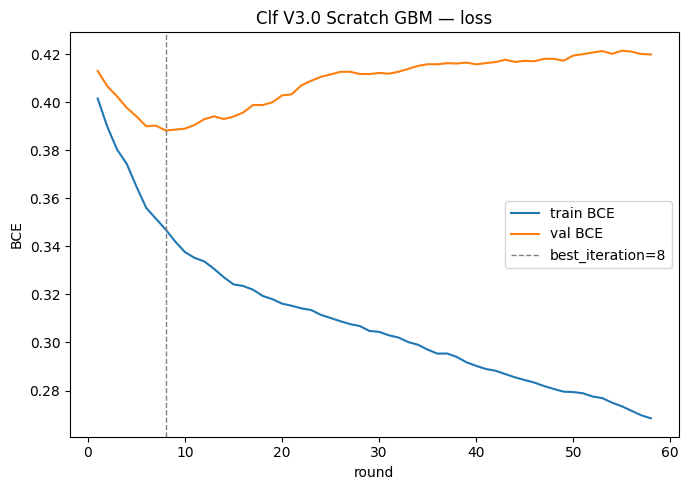

In [18]:
plt.figure(figsize=(7, 5))
plt.plot(history["round"], history["train_metric"], label="train BCE")
plt.plot(history["round"], history["val_metric"], label="val BCE")
plt.axvline(best_round, color="gray", linestyle="--", linewidth=1, label=f"best_iteration={best_round}")
plt.xlabel("round"); plt.ylabel("BCE"); plt.legend()
plt.title("Clf V3.0 Scratch GBM — loss")
plt.tight_layout()
plt.savefig("media/loss_clf_V3_0.png", dpi=150)
plt.show()

## Parity Check

In [19]:
lib = json.load(open("weights_V3_0/classification_lightgbm_test_metrics.json"))
scr = json.load(open("weights_V3_0/classification_scratch_test_metrics.json"))
for k in ("test_loss_BCE", "accuracy", "precision", "recall", "f1", "roc_auc"):
    print(f"{k:<14}{lib[k]:>9}{scr[k]:>9}  absΔ={abs(scr[k]-lib[k]):.4f}")
loss_ok = abs(scr["test_loss_BCE"] - lib["test_loss_BCE"]) < 0.05
f1_ok = abs(scr["f1"] - lib["f1"]) < 0.05
print("\nPARITY V3.0 (library vs scratch):", "PASS" if (loss_ok and f1_ok) else "FAIL")

test_loss_BCE    0.2967   0.3757  absΔ=0.0790
accuracy         0.8728   0.8504  absΔ=0.0224
precision        0.5658      0.0  absΔ=0.5658
recall           0.6418      0.0  absΔ=0.6418
f1               0.6014      0.0  absΔ=0.6014
roc_auc          0.8898    0.831  absΔ=0.0588

PARITY V3.0 (library vs scratch): FAIL
